# Pipeline Final — Détection & Rapport Mammographie DMID

```
Image → U-Net → masque + crop → EfficientNet-B3 → Bénin/Malin
                  masque précis → MedGemma       → Rapport structuré
```

| Composant | Rôle | Modèle |
|---|---|---|
| **U-Net** | Segmentation lésion → masque binaire | ResNet34 encoder, fine-tuné DMID |
| **EfficientNet-B3** | Classification B/M depuis crop U-Net | ImageNet + SVM, fine-tuné DMID |
| **OpenCV** | Features radiologiques depuis masque | Morphologie, texture, contraste |
| **MedGemma-4B** | Génération rapport structuré | google/medgemma-4b-it |

**Évaluation :**
- Classification → Matrice de confusion, AUC, Sensibilité, Spécificité
- Rapport → ROUGE-1/2/L + BLEU-1/2/4 vs rapports de référence (`Reports/*.txt`)


In [1]:
import sys
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    print('Drive monté.')
else:
    print('Environnement local.')


Mounted at /content/drive
Drive monté.


In [2]:
!pip install -q timm segmentation-models-pytorch
!pip install -q transformers accelerate bitsandbytes
!pip install -q rouge-score nltk opencv-python-headless
!pip install -q openpyxl scikit-learn matplotlib seaborn joblib
!pip install -q sentence-transformers
import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
print('Installation OK')


In [27]:
# MedGemma requires accepting Google's terms of use on Hugging Face:
#   https://huggingface.co/google/medgemma-4b-it
# Store your token as a Colab secret named HF_TOKEN (key icon in the left panel),
# or as an environment variable. Never paste a token in the notebook.
import os
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get('HF_TOKEN')
except Exception:
    HF_TOKEN = os.environ.get('HF_TOKEN')

from huggingface_hub import login
if HF_TOKEN:
    login(token=HF_TOKEN, add_to_git_credential=False)
    print('Connected to Hugging Face.')
else:
    print('HF_TOKEN missing: MedGemma cannot be loaded.')

HuggingFace connecté.


In [28]:
import os, warnings, random, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path
from PIL import Image, ImageDraw
from copy import deepcopy
import cv2
import joblib

import torch
import torch.nn.functional as F
import torchvision.transforms as T
import timm
import segmentation_models_pytorch as smp

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score,
                              confusion_matrix, classification_report,
                              roc_curve, ConfusionMatrixDisplay)

from rouge_score import rouge_scorer as rs
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

from transformers import AutoProcessor, AutoModelForImageTextToText, BitsAndBytesConfig

warnings.filterwarnings('ignore')
torch.manual_seed(42); np.random.seed(42); random.seed(42)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Device: cuda


In [29]:
PFA_PATH     = '/content/drive/MyDrive/PFA'   # Colab
# PFA_PATH   = r'd:\\PFA'                    # Local

DATASET_PATH = os.path.join(PFA_PATH, 'DMID')
METADATA_XLS = os.path.join(DATASET_PATH, 'Metadata.xlsx')
IMG_DIR      = os.path.join(DATASET_PATH, '512', 'TIFF')
MASK_DIR     = os.path.join(DATASET_PATH, '512', 'Mask')
REPORTS_DIR  = os.path.join(DATASET_PATH, 'Reports')
MODELS_DIR   = os.path.join(PFA_PATH, 'models')
UNET_PT      = os.path.join(MODELS_DIR, 'unet_mammo.pt')
MEDGEMMA_ID  = 'google/medgemma-4b-it'

SEG_SIZE = 256
EFF_PAD  = 3.0

SEG_TF = T.Compose([
    T.Resize((SEG_SIZE, SEG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])
FEAT_TF = T.Compose([
    T.Resize((300, 300)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

os.makedirs(MODELS_DIR, exist_ok=True)
print('Configuration OK')
print(f'  Images  : {IMG_DIR}')
print(f'  Masques : {MASK_DIR}')
print(f'  Reports : {REPORTS_DIR}')


Configuration OK
  Images  : /content/drive/MyDrive/PFA/DMID/512/TIFF
  Masques : /content/drive/MyDrive/PFA/DMID/512/Mask
  Reports : /content/drive/MyDrive/PFA/DMID/Reports


In [30]:
df_raw = pd.read_excel(METADATA_XLS, header=None, skiprows=31,
                       names=['ref','view','tissue','abnormality',
                               'class','cx','cy','radius'])
VALID = {'B','M','N'}
df = df_raw[df_raw['class'].astype(str).str.strip().isin(VALID)].copy()
for col in ['class','ref','view','tissue']:
    df[col] = df[col].astype(str).str.strip()
for col in ['cx','cy','radius']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df_bm = df[df['class'].isin(['B','M'])].dropna(subset=['cx','cy','radius']).copy()
df_bm['label'] = (df_bm['class'] == 'M').astype(int)

def get_img_path(ref):
    for cand in [Path(IMG_DIR)/f'{ref}.png',
                 Path(IMG_DIR)/f'{ref.upper()}.png',
                 Path(IMG_DIR)/f'{ref.lower()}.png']:
        if cand.exists(): return str(cand)
    hits = list(Path(IMG_DIR).glob(f'*{ref}*.png'))
    if hits: return str(hits[0])
    # Essayer .tif / .tiff
    for ext in ['.tif','.tiff','.TIF','.TIFF']:
        p = Path(IMG_DIR)/f'{ref}{ext}'
        if p.exists(): return str(p)
    hits = list(Path(IMG_DIR).glob(f'*{ref}*'))
    return str(hits[0]) if hits else None

def get_report_path(ref):
    # Essais directs
    for cand in [Path(REPORTS_DIR)/f'{ref}.txt',
                 Path(REPORTS_DIR)/f'{ref.upper()}.txt',
                 Path(REPORTS_DIR)/f'{ref.lower()}.txt']:
        if cand.exists(): return str(cand)
    # Cas DMID : ref='IMG145' → fichier='Img145.txt'
    m = re.search(r'(\d+)', ref)
    if m:
        num = m.group(1)
        for prefix in ['Img', 'img', 'IMG', 'image', 'Image']:
            cand = Path(REPORTS_DIR) / f'{prefix}{num}.txt'
            if cand.exists(): return str(cand)
    # Glob insensible à la casse via itération
    ref_lower = ref.lower()
    for p in Path(REPORTS_DIR).glob('*.txt'):
        if p.stem.lower() == ref_lower:
            return str(p)
    # Glob partiel (dernier recours)
    hits = [p for p in Path(REPORTS_DIR).glob('*.txt')
            if ref.lower() in p.stem.lower()]
    return str(hits[0]) if hits else None

# COORD_SX auto-détection
_s_path = get_img_path(df_bm['ref'].iloc[0])
if _s_path:
    _W, _H = Image.open(_s_path).size
    _cx_max, _cy_max = df_bm['cx'].max(), df_bm['cy'].max()
    COORD_SX = (_W/_cx_max) if _cx_max > _W else 1.0
    COORD_SY = (_H/_cy_max) if _cy_max > _H else 1.0
else:
    COORD_SX = COORD_SY = 1.0

print(f'Annotations B+M : {len(df_bm)}  |  Images : {df_bm["ref"].nunique()}')
print(f'COORD_SX={COORD_SX:.4f}  COORD_SY={COORD_SY:.4f}')


Annotations B+M : 408  |  Images : 274
COORD_SX=0.1090  COORD_SY=0.0144


In [31]:
ref_cls = df_bm.groupby('ref')['class'].agg(lambda x: x.mode()[0]).reset_index()
refs, labels = ref_cls['ref'].values, ref_cls['class'].values

r_train, r_temp, _, l_temp = train_test_split(
    refs, labels, test_size=0.30, stratify=labels, random_state=42)
r_val, r_test, _, _ = train_test_split(
    r_temp, l_temp, test_size=0.50, stratify=l_temp, random_state=42)

train_df = df_bm[df_bm['ref'].isin(r_train)].reset_index(drop=True)
val_df   = df_bm[df_bm['ref'].isin(r_val)].reset_index(drop=True)
test_df  = df_bm[df_bm['ref'].isin(r_test)].reset_index(drop=True)

def make_img_df(refs_list, df_les):
    rows = []
    for ref in refs_list:
        sub = df_les[df_les['ref']==ref]
        if sub.empty: continue
        row0 = sub.iloc[0]
        rows.append({'ref': ref, 'label': int(sub['label'].max()),
                     'view': row0['view'], 'tissue': row0['tissue']})
    return pd.DataFrame(rows).reset_index(drop=True)

img_train = make_img_df(r_train, train_df)
img_val   = make_img_df(r_val,   val_df)
img_test  = make_img_df(r_test,  test_df)

print(f'Split — Train:{len(img_train)}  Val:{len(img_val)}  Test:{len(img_test)} images')
print(f'Test labels : {(img_test.label==0).sum()} Bénin / {(img_test.label==1).sum()} Malin')


Split — Train:191  Val:41  Test:42 images
Test labels : 23 Bénin / 19 Malin


In [32]:
unet = smp.Unet('resnet34', encoder_weights=None,
                in_channels=3, classes=1, activation=None).to(DEVICE)
unet.load_state_dict(torch.load(UNET_PT, map_location=DEVICE))
unet.eval()
print(f'U-Net chargé : {UNET_PT}')


U-Net chargé : /content/drive/MyDrive/PFA/models/unet_mammo.pt


In [33]:
def run_unet(img_pil):
    """Retourne masque float32 (H,W) à la résolution de l'image originale."""
    W, H = img_pil.size
    img_t = SEG_TF(img_pil).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        mask256 = torch.sigmoid(unet(img_t))[0,0].cpu().numpy()  # (256,256)
    return cv2.resize(mask256, (W, H), interpolation=cv2.INTER_LINEAR)

def mask_to_crop(img_pil, mask_full, pad=EFF_PAD):
    """Crop image + masque à partir de la bounding box U-Net."""
    W, H = img_pil.size
    binary = mask_full > 0.5
    rows   = np.where(binary.any(1))[0]
    cols   = np.where(binary.any(0))[0]
    if len(rows) == 0:
        return img_pil, mask_full, (0, 0, W, H)   # fallback image entière
    x1, x2 = int(cols[0]), int(cols[-1])
    y1, y2 = int(rows[0]), int(rows[-1])
    cx=(x1+x2)//2; cy=(y1+y2)//2
    r=max((x2-x1)//2,(y2-y1)//2)
    rp=int(r*pad)
    x1p=max(0,cx-rp); y1p=max(0,cy-rp)
    x2p=min(W,cx+rp); y2p=min(H,cy+rp)
    bbox = (x1p, y1p, x2p, y2p)
    img_crop  = img_pil.crop(bbox)
    mask_crop = mask_full[y1p:y2p, x1p:x2p]
    return img_crop, mask_crop, bbox

def extract_radiomic(mask_float, img_pil):
    """12 features radiologiques depuis masque U-Net."""
    H, W = mask_float.shape
    mask_bin = (mask_float > 0.5).astype(np.uint8) * 255
    img_gray = np.array(img_pil.convert('L'), dtype=np.float32)
    feats = np.zeros(12, dtype=np.float32)
    contours, _ = cv2.findContours(mask_bin, cv2.RETR_EXTERNAL,
                                   cv2.CHAIN_APPROX_SIMPLE)
    if not contours: return feats
    cnt  = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(cnt)
    if area < 4: return feats
    perim = cv2.arcLength(cnt, True) + 1e-8
    circ  = 4*np.pi*area / (perim**2)
    hull  = cv2.convexHull(cnt)
    solid = area / (cv2.contourArea(hull)+1e-8)
    x,y,w,h = cv2.boundingRect(cnt)
    aspect = w/(h+1e-8); extent = area/(w*h+1e-8)
    M = cv2.moments(cnt)
    if M['m00']>0:
        mu20=M['mu20']/M['m00']; mu02=M['mu02']/M['m00']; mu11=M['mu11']/M['m00']
        d=np.sqrt((mu20-mu02)**2+4*mu11**2)
        lam1=(mu20+mu02+d)/2+1e-8; lam2=(mu20+mu02-d)/2
        ecc=float(np.sqrt(max(0,1-lam2/lam1)))
    else: ecc=0.
    inside  = img_gray[mask_bin>0]; outside = img_gray[mask_bin==0]
    mean_in  = inside.mean()  if len(inside)>0  else 0.
    std_in   = inside.std()   if len(inside)>0  else 0.
    mean_out = outside.mean() if len(outside)>0 else 0.
    contrast = mean_in/(mean_out+1e-8)
    feats = np.array([area/(H*W), circ, solid, ecc, aspect, extent,
                      mean_in, std_in, mean_out, contrast,
                      np.log1p(area), np.log1p(perim)], dtype=np.float32)
    return feats

def make_overlay(img_pil, mask_float, alpha=0.40):
    """Superpose le masque U-Net en rouge semi-transparent sur l'image."""
    img_arr = np.array(img_pil.convert('RGB')).astype(np.float32)
    m = mask_float > 0.5
    img_arr[m, 0] = np.clip(img_arr[m, 0]*(1-alpha)+255*alpha, 0, 255)
    img_arr[m, 1] = np.clip(img_arr[m, 1]*(1-alpha), 0, 255)
    img_arr[m, 2] = np.clip(img_arr[m, 2]*(1-alpha), 0, 255)
    return Image.fromarray(img_arr.astype(np.uint8))

print('Fonctions pipeline OK')


Fonctions pipeline OK


In [34]:
# Extracteur EfficientNet-B3
feat_ext = timm.create_model('efficientnet_b3', pretrained=True, num_classes=0).to(DEVICE).eval()
print('EfficientNet-B3 chargé (extracteur features 1536-dim)')

def extract_unet_features(df_img):
    feats, ys = [], []
    for _, row in df_img.iterrows():
        path = get_img_path(row['ref'])
        if path is None: continue
        img      = Image.open(path).convert('RGB')
        mask_f   = run_unet(img)
        crop, _, _ = mask_to_crop(img, mask_f)
        t = FEAT_TF(crop).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            f = feat_ext(t).cpu().numpy()
        feats.append(f[0]); ys.append(row['label'])
    return np.array(feats), np.array(ys)

print('Extraction features Train...')
X_tr, y_tr = extract_unet_features(img_train)
print('Extraction features Val...')
X_va, y_va = extract_unet_features(img_val)
print('Extraction features Test...')
X_te, y_te = extract_unet_features(img_test)

X_tv = np.vstack([X_tr, X_va])
y_tv = np.concatenate([y_tr, y_va])

from imblearn.over_sampling import SMOTE
from collections import Counter

scaler = StandardScaler()
X_tv_s = scaler.fit_transform(X_tv)
X_te_s = scaler.transform(X_te)

# SMOTE sur Train+Val uniquement (jamais sur Test)
k_smote = min(Counter(y_tv).values()) - 1
smote   = SMOTE(random_state=42, k_neighbors=max(1, k_smote))
X_tv_sm, y_tv_sm = smote.fit_resample(X_tv_s, y_tv)
print(f'SMOTE : {Counter(y_tv)} → {Counter(y_tv_sm)}')

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
candidates = {
    'SVM RBF C=10': SVC(C=10, kernel='rbf', class_weight='balanced',
                        probability=True, random_state=42),
    'SVM RBF C=1':  SVC(C=1,  kernel='rbf', class_weight='balanced',
                        probability=True, random_state=42),
    'LogReg C=0.1': LogisticRegression(C=0.1, class_weight='balanced',
                                       max_iter=1000, random_state=42),
}
best_cv, best_clf = 0., None
for name, clf in candidates.items():
    sc = cross_val_score(clf, X_tv_sm, y_tv_sm, cv=skf, scoring='roc_auc', n_jobs=-1)
    print(f'  {name}: CV AUC = {sc.mean():.3f} ± {sc.std():.3f}')
    if sc.mean() > best_cv:
        best_cv  = sc.mean()
        best_clf = deepcopy(clf)

best_clf.fit(X_tv_sm, y_tv_sm)
te_probs = best_clf.predict_proba(X_te_s)[:, 1]
te_preds = (te_probs >= 0.5).astype(int)
te_auc   = roc_auc_score(y_te, te_probs)
print(f'\nEfficientNet-B3 + SVM + SMOTE (U-Net crop)')
print(f'  CV AUC  : {best_cv:.4f}')
print(f'  Test AUC: {te_auc:.4f}')

joblib.dump({'clf': best_clf, 'scaler': scaler},
           os.path.join(MODELS_DIR,'effnet_unet_classifier.pkl'))
print('Classifieur sauvegardé : effnet_unet_classifier.pkl')


EfficientNet-B3 chargé (extracteur features 1536-dim)
Extraction features Train...
Extraction features Val...
Extraction features Test...
SMOTE : Counter({np.int64(0): 123, np.int64(1): 109}) → Counter({np.int64(0): 123, np.int64(1): 123})
  SVM RBF C=10: CV AUC = 0.804 ± 0.055
  SVM RBF C=1: CV AUC = 0.773 ± 0.073
  LogReg C=0.1: CV AUC = 0.800 ± 0.079

EfficientNet-B3 + SVM + SMOTE (U-Net crop)
  CV AUC  : 0.8045
  Test AUC: 0.8032
Classifieur sauvegardé : effnet_unet_classifier.pkl


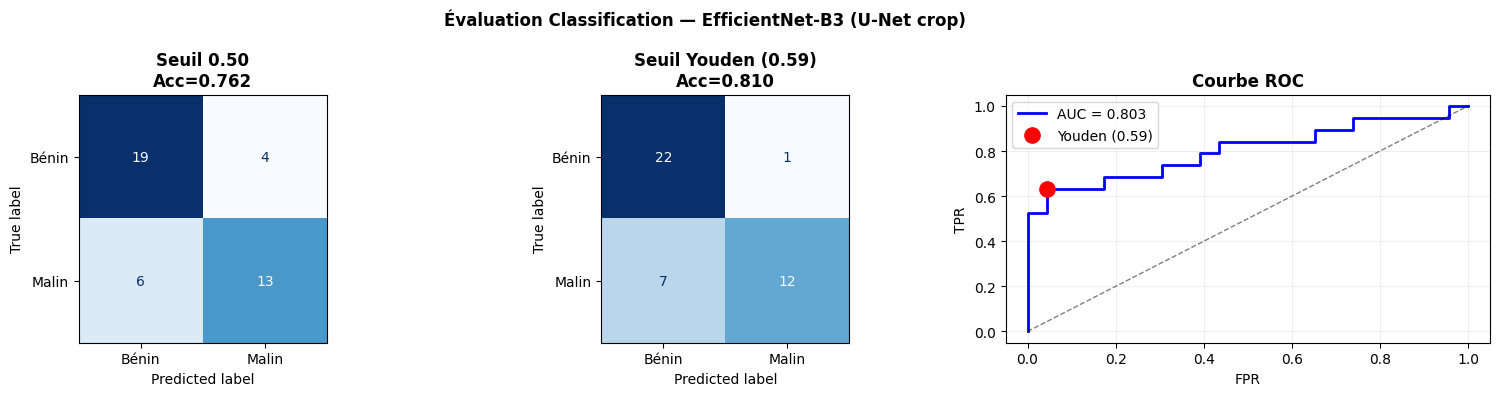

=== Rapport de classification ===
              precision    recall  f1-score   support

       Bénin       0.76      0.96      0.85        23
       Malin       0.92      0.63      0.75        19

    accuracy                           0.81        42
   macro avg       0.84      0.79      0.80        42
weighted avg       0.83      0.81      0.80        42

Sensibilité (Recall Malin) : 0.6316
Spécificité               : 0.9565
VPP                       : 0.9231
VPN                       : 0.7586


In [35]:
from sklearn.metrics import roc_curve

# Seuil optimal Youden
fpr, tpr, thrs = roc_curve(y_te, te_probs)
best_thr = float(thrs[np.argmax(tpr - fpr)])
te_preds_opt = (te_probs >= best_thr).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# ── Matrice de confusion seuil 0.5 ───────────────────────────────────────────
for ax, preds, thr_name in [
    (axes[0], te_preds,     'Seuil 0.50'),
    (axes[1], te_preds_opt, f'Seuil Youden ({best_thr:.2f})'),
]:
    cm = confusion_matrix(y_te, preds)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Bénin','Malin'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    acc = accuracy_score(y_te, preds)
    ax.set_title(f'{thr_name}\nAcc={acc:.3f}', fontweight='bold')

# ── Courbe ROC ────────────────────────────────────────────────────────────────
axes[2].plot(fpr, tpr, 'b-', lw=2, label=f'AUC = {te_auc:.3f}')
axes[2].plot([0,1],[0,1],'k--',lw=1,alpha=0.5)
axes[2].scatter(fpr[np.argmax(tpr-fpr)], tpr[np.argmax(tpr-fpr)],
                s=120, color='red', zorder=5,
                label=f'Youden ({best_thr:.2f})')
axes[2].set_xlabel('FPR'); axes[2].set_ylabel('TPR')
axes[2].set_title('Courbe ROC', fontweight='bold')
axes[2].legend(); axes[2].grid(alpha=0.2)

plt.suptitle('Évaluation Classification — EfficientNet-B3 (U-Net crop)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(PFA_PATH,'confusion_roc.png'),dpi=150,bbox_inches='tight')
plt.show()

print('=== Rapport de classification ===')
print(classification_report(y_te, te_preds_opt,
                             target_names=['Bénin','Malin']))
cm = confusion_matrix(y_te, te_preds_opt)
tn,fp,fn,tp = cm.ravel()
print(f'Sensibilité (Recall Malin) : {tp/(tp+fn+1e-8):.4f}')
print(f'Spécificité               : {tn/(tn+fp+1e-8):.4f}')
print(f'VPP                       : {tp/(tp+fp+1e-8):.4f}')
print(f'VPN                       : {tn/(tn+fn+1e-8):.4f}')


## MedGemma — Génération de Rapport

**google/medgemma-4b-it** est un modèle multimodal (image+texte) pré-entraîné
sur des données médicales : radiographies, pathologie, textes cliniques.

**Input fourni à MedGemma :**
- Crop de la lésion avec overlay rouge du masque U-Net
- Résultat de classification EfficientNet (B/M + probabilité)
- Features radiologiques OpenCV (forme, texture, contraste)

**Output attendu (structure obligatoire) :**
```
## CLINICAL INDICATION
## TECHNIQUE
## FINDINGS      ← section obligatoire évaluée par ROUGE/BLEU
## IMPRESSION
```


In [36]:
bnb_cfg = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type='nf4'
)

print(f'Chargement MedGemma : {MEDGEMMA_ID}')
medgemma_proc = AutoProcessor.from_pretrained(MEDGEMMA_ID, token=HF_TOKEN)
medgemma = AutoModelForImageTextToText.from_pretrained(
    MEDGEMMA_ID,
    quantization_config=bnb_cfg,
    device_map='auto',
    token=HF_TOKEN
)
medgemma.eval()
print('MedGemma chargé (4-bit quantization)')
print(f'Params : {sum(p.numel() for p in medgemma.parameters()):,}')


Chargement MedGemma : google/medgemma-4b-it


processor_config.json:   0%|          | 0.00/70.0 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.47k [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/90.6k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

MedGemma chargé (4-bit quantization)
Params : 2,490,222,960


In [37]:
def build_prompt(ref, view, tissue, cls_label, prob, feats):
    """
    Construit le prompt MedGemma — format identique aux rapports GT DMID.
    """
    circ   = feats[1]; solid = feats[2]
    std_in = feats[7]

    if circ > 0.80:   shape = 'round'
    elif circ > 0.60: shape = 'oval'
    else:             shape = 'irregular'

    if solid > 0.85:   margins = 'well-defined'
    elif solid > 0.70: margins = 'partially ill-defined'
    else:              margins = 'ill-defined'

    heter = 'heterogeneous' if std_in > 30 else 'homogeneous'

    # BIRADS et description lésion selon classification
    if cls_label == 1:
        birads_str  = '5' if prob >= 0.85 else '4'
        lesion_line = (f'{shape} {margins} soft opacity with {heter} internal texture '
                       f'suggests malignant lesion (BIRADS-{birads_str})')
    else:
        birads_str  = '2' if prob <= 0.25 else '3'
        lesion_line = (f'{shape} well-defined soft nodular opacity -- '
                       f'benign lesion (BIRADS-{birads_str})')

    # ACR density depuis tissue metadata
    t_low = str(tissue).lower()
    if 'dense' in t_low and 'hetero' in t_low:
        acr = 'C'; comp = 'heterogeneously dense breast parenchyma'
    elif 'dense' in t_low:
        acr = 'D'; comp = 'extremely dense breast parenchyma'
    elif 'fibro' in t_low or 'gland' in t_low:
        acr = 'B'; comp = 'fibro fatty and scattered glandular breast parenchyma'
    else:
        acr = 'B'; comp = 'predominantly fibro fatty breast parenchyma'

    return f"""You are a specialist radiologist writing a mammography report for patient {ref} ({view} view).

Automated segmentation and classification results:
- Classification: {'MALIGNANT' if cls_label==1 else 'BENIGN'} (confidence {prob*100:.1f}%)
- Lesion shape: {shape}, margins: {margins}, texture: {heter}
- Tissue density: {tissue} → ACR {acr}

Generate the report in EXACTLY this format (no markdown, no extra headers):

Breast Composition:
{comp} (ACR {acr})

BIRADS: {birads_str}

Findings:
{lesion_line}
[describe calcifications if visible: benign/vascular calcifications OR microcalcifications OR 'No suspicious calcifications']
Skin and nipple - [write 'no abnormality' or describe if abnormal]
[write 'No axillary adenopathy' OR 'Benign looking axillary adenopathy' OR describe if abnormal]
"""

def generate_report(overlay_pil, prompt_text, max_tokens=350):
    """Génère un rapport depuis MedGemma."""
    messages = [
        {"role": "user", "content": [
            {"type": "image", "image": overlay_pil},
            {"type": "text",  "text": prompt_text}
        ]}
    ]
    inputs = medgemma_proc.apply_chat_template(
        messages, add_generation_prompt=True,
        tokenize=True, return_dict=True, return_tensors='pt'
    )
    inputs = {k: v.to(medgemma.device) for k, v in inputs.items()}
    with torch.no_grad():
        out = medgemma.generate(
            **inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            temperature=1.0,
            repetition_penalty=1.1
        )
    n_inp = inputs['input_ids'].shape[1]
    return medgemma_proc.decode(out[0][n_inp:], skip_special_tokens=True)

def extract_findings_section(report_text):
    """Extrait tout depuis Findings: jusqu'à la fin (inclut Skin/nipple + axillary)."""
    m = re.search(r'Findings?\s*:\s*\n?(.*)',
                  report_text, re.DOTALL | re.IGNORECASE)
    return m.group(1).strip() if m else report_text.strip()

print('Fonctions génération rapport OK')


Fonctions génération rapport OK


In [38]:
ref_reports = {}   # ref → texte de référence
n_found = 0

if os.path.isdir(REPORTS_DIR):
    for _, row in img_test.iterrows():
        rpath = get_report_path(row['ref'])
        if rpath:
            text = Path(rpath).read_text(encoding='utf-8', errors='ignore').strip()
            if text:
                ref_reports[row['ref']] = text
                n_found += 1
    print(f'Rapports de référence trouvés : {n_found} / {len(img_test)}')
    if n_found > 0:
        # Aperçu du premier rapport
        first_ref, first_txt = next(iter(ref_reports.items()))
        print(f'\nExemple ({first_ref}) :')
        print(first_txt[:500] + '...' if len(first_txt)>500 else first_txt)
else:
    print(f'Dossier Reports introuvable : {REPORTS_DIR}')
    print('ROUGE/BLEU ne pourra pas être calculé.')


Rapports de référence trouvés : 42 / 42

Exemple (IMG145) :
Breast Composition:
fibro fatty and glandular breast parenchyma (ACR B).

BIRADS: 2

Findings:
a benign-looking popcorn calcification is seen in the central quadrant.(BIRADS 2)
skin, nipple, and pectoral muscle appear normal.
benign-looking axillary adenopathy.


In [39]:
import time as _time_pipe

# Génération de tous les rapports sur le test set
pipeline_results = []

print(f'Pipeline sur {len(img_test)} images test...')
print('(U-Net → crop → EfficientNet → MedGemma)')
print()

t0_pipe = _time_pipe.time()

for i, row in img_test.iterrows():
    ref     = row['ref']
    view    = row.get('view','MLO')
    tissue  = row.get('tissue','heterogeneous')
    true_lb = row['label']
    path    = get_img_path(ref)
    if path is None:
        print(f'  [{i+1}] {ref} — image introuvable, ignoré')
        continue

    img = Image.open(path).convert('RGB')

    # 1. U-Net → masque
    mask_f = run_unet(img)

    # 2. Crop depuis bounding box U-Net
    crop, mask_crop, bbox = mask_to_crop(img, mask_f)

    # 3. EfficientNet → classification
    t    = FEAT_TF(crop).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        feat = feat_ext(t).cpu().numpy()
    feat_s = scaler.transform(feat)
    prob   = float(best_clf.predict_proba(feat_s)[0, 1])
    pred   = int(prob >= best_thr)

    # 4. Features radiologiques
    feats_r = extract_radiomic(mask_f, img)

    # 5. Overlay pour MedGemma
    overlay = make_overlay(crop, mask_crop)

    # 6. MedGemma → rapport
    prompt  = build_prompt(ref, view, tissue, pred, prob, feats_r)
    report  = generate_report(overlay, prompt)
    findings = extract_findings_section(report)

    pipeline_results.append({
        'ref':      ref,
        'true':     true_lb,
        'pred':     pred,
        'prob':     prob,
        'report':   report,
        'findings': findings,
        'crop':     crop,
        'mask':     mask_f,
        'overlay':  overlay,
        'feats_r':  feats_r,
    })

    correct = '✓' if pred == true_lb else '✗'
    cls_str = 'Malin' if pred==1 else 'Bénin'
    print(f'  [{i+1:2d}/{len(img_test)}] {ref[:18]:<20} '
          f'GT:{"M" if true_lb==1 else "B"}  '
          f'Pred:{cls_str} ({prob:.2f}) {correct}')

t1_pipe = _time_pipe.time()
elapsed_pipe = t1_pipe - t0_pipe
n_proc = len(pipeline_results)
print(f'\n✓ Pipeline terminé : {n_proc} images traitées')
print(f'Execution Time total : {elapsed_pipe:.2f}s '
      f'({elapsed_pipe/max(n_proc,1)*1000:.0f}ms/image)')


Pipeline sur 42 images test...
(U-Net → crop → EfficientNet → MedGemma)

  [ 1/42] IMG145               GT:B  Pred:Bénin (0.34) ✓
  [ 2/42] IMG008               GT:B  Pred:Bénin (0.13) ✓
  [ 3/42] IMG011               GT:B  Pred:Bénin (0.59) ✓
  [ 4/42] IMG358               GT:B  Pred:Bénin (0.23) ✓
  [ 5/42] IMG044               GT:M  Pred:Malin (0.72) ✓
  [ 6/42] IMG102               GT:B  Pred:Bénin (0.23) ✓
  [ 7/42] IMG471               GT:M  Pred:Malin (0.86) ✓
  [ 8/42] IMG423               GT:B  Pred:Bénin (0.15) ✓
  [ 9/42] IMG443               GT:M  Pred:Malin (0.66) ✓
  [10/42] IMG290               GT:B  Pred:Bénin (0.43) ✓
  [11/42] IMG292               GT:B  Pred:Bénin (0.49) ✓
  [12/42] IMG220               GT:M  Pred:Malin (0.59) ✓
  [13/42] IMG150               GT:B  Pred:Bénin (0.49) ✓
  [14/42] IMG355               GT:B  Pred:Bénin (0.29) ✓
  [15/42] IMG460               GT:B  Pred:Bénin (0.35) ✓
  [16/42] IMG483               GT:M  Pred:Malin (0.72) ✓
  [17/42] IMG28

In [40]:
import time as _time_eval
from sentence_transformers import SentenceTransformer
import torch.nn.functional as F_

def extract_ref_findings(ref_text):
    """Extrait tout depuis Findings: jusqu'à la fin (inclut Skin/nipple + axillary)."""
    m = re.search(
        r'Findings?\s*:\s*\n?(.*)',
        ref_text, re.DOTALL | re.IGNORECASE
    )
    return m.group(1).strip() if m else ref_text.strip()

# ── Chargement BERT (sentence-transformers) ───────────────────────────────────
print('Chargement SentenceTransformer ...')
bert_model = SentenceTransformer('paraphrase-MiniLM-L6-v2')
print('  OK\n')

rouge_scorer_obj = rs.RougeScorer(
    ['rouge1','rouge2','rougeL'], use_stemmer=True)
smooth = SmoothingFunction().method1

rouge_scores = {'rouge1':[], 'rouge2':[], 'rougeL':[]}
bleu_scores  = {'bleu1':[], 'bleu2':[], 'bleu4':[]}
bert_sims    = []
n_evaluated  = 0

print('Évaluation ROUGE / BLEU / BERT-Cosine (Findings généré vs Findings référence)')
print()

t0_eval = _time_eval.time()

for res in pipeline_results:
    ref_text = ref_reports.get(res['ref'])
    if ref_text is None:
        continue

    hyp     = res['findings']
    ref_fin = extract_ref_findings(ref_text)

    # ROUGE
    scores = rouge_scorer_obj.score(ref_fin, hyp)
    rouge_scores['rouge1'].append(scores['rouge1'].fmeasure)
    rouge_scores['rouge2'].append(scores['rouge2'].fmeasure)
    rouge_scores['rougeL'].append(scores['rougeL'].fmeasure)

    # BLEU
    ref_toks = [ref_fin.lower().split()]
    hyp_toks = hyp.lower().split()
    if len(hyp_toks) >= 4:
        bleu_scores['bleu1'].append(
            sentence_bleu(ref_toks, hyp_toks, weights=(1,0,0,0),        smoothing_function=smooth))
        bleu_scores['bleu2'].append(
            sentence_bleu(ref_toks, hyp_toks, weights=(0.5,0.5,0,0),    smoothing_function=smooth))
        bleu_scores['bleu4'].append(
            sentence_bleu(ref_toks, hyp_toks, weights=(.25,.25,.25,.25), smoothing_function=smooth))

    # BERT Cosine Similarity
    emb_hyp = bert_model.encode(hyp,     convert_to_tensor=True, show_progress_bar=False)
    emb_ref = bert_model.encode(ref_fin, convert_to_tensor=True, show_progress_bar=False)
    sim = float(F_.cosine_similarity(emb_hyp.unsqueeze(0), emb_ref.unsqueeze(0)))
    bert_sims.append(sim)

    n_evaluated += 1

t1_eval = _time_eval.time()
elapsed_eval = t1_eval - t0_eval

print(f'Images évaluées  : {n_evaluated} / {len(pipeline_results)}')
print(f'Execution Time   : {elapsed_eval:.2f}s  '
      f'({elapsed_eval/max(n_evaluated,1)*1000:.1f}ms/rapport)')
print()
print('=== ROUGE scores (Findings généré  vs  Findings référence) ===')
for k, v in rouge_scores.items():
    if v:
        print(f'  {k.upper():<10} : {np.mean(v):.4f} ± {np.std(v):.4f}')
    else:
        print(f'  {k.upper():<10} : N/A')

print('\n=== BLEU scores ===')
for k, v in bleu_scores.items():
    if v:
        print(f'  {k.upper():<10} : {np.mean(v):.4f} ± {np.std(v):.4f}')
    else:
        print(f'  {k.upper():<10} : N/A')

print('\n=== BERT Cosine Similarity ===')
if bert_sims:
    print(f'  BERT-Cosine : {np.mean(bert_sims):.4f} ± {np.std(bert_sims):.4f}')
else:
    print('  BERT-Cosine : N/A')

if n_evaluated == 0:
    print('\n⚠️  Aucun rapport de référence associé aux images test.')
    print('   Correspondance attendue : IMG145 → Img145.txt')
    if os.path.isdir(REPORTS_DIR):
        avail = sorted(Path(REPORTS_DIR).glob('*.txt'))[:10]
        print(f'   Fichiers dispo  : {[p.name for p in avail]}')
    print(f'   Refs test       : {img_test["ref"].tolist()[:8]}')


Chargement SentenceTransformer ...


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.51k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

  OK

Évaluation ROUGE / BLEU / BERT-Cosine (Findings généré vs Findings référence)

Images évaluées  : 42 / 42
Execution Time   : 0.75s  (17.8ms/rapport)

=== ROUGE scores (Findings généré  vs  Findings référence) ===
  ROUGE1     : 0.4418 ± 0.0862
  ROUGE2     : 0.2038 ± 0.0913
  ROUGEL     : 0.3743 ± 0.0966

=== BLEU scores ===
  BLEU1      : 0.2383 ± 0.1262
  BLEU2      : 0.1368 ± 0.1118
  BLEU4      : 0.0505 ± 0.0758

=== BERT Cosine Similarity ===
  BERT-Cosine : 0.7145 ± 0.0828


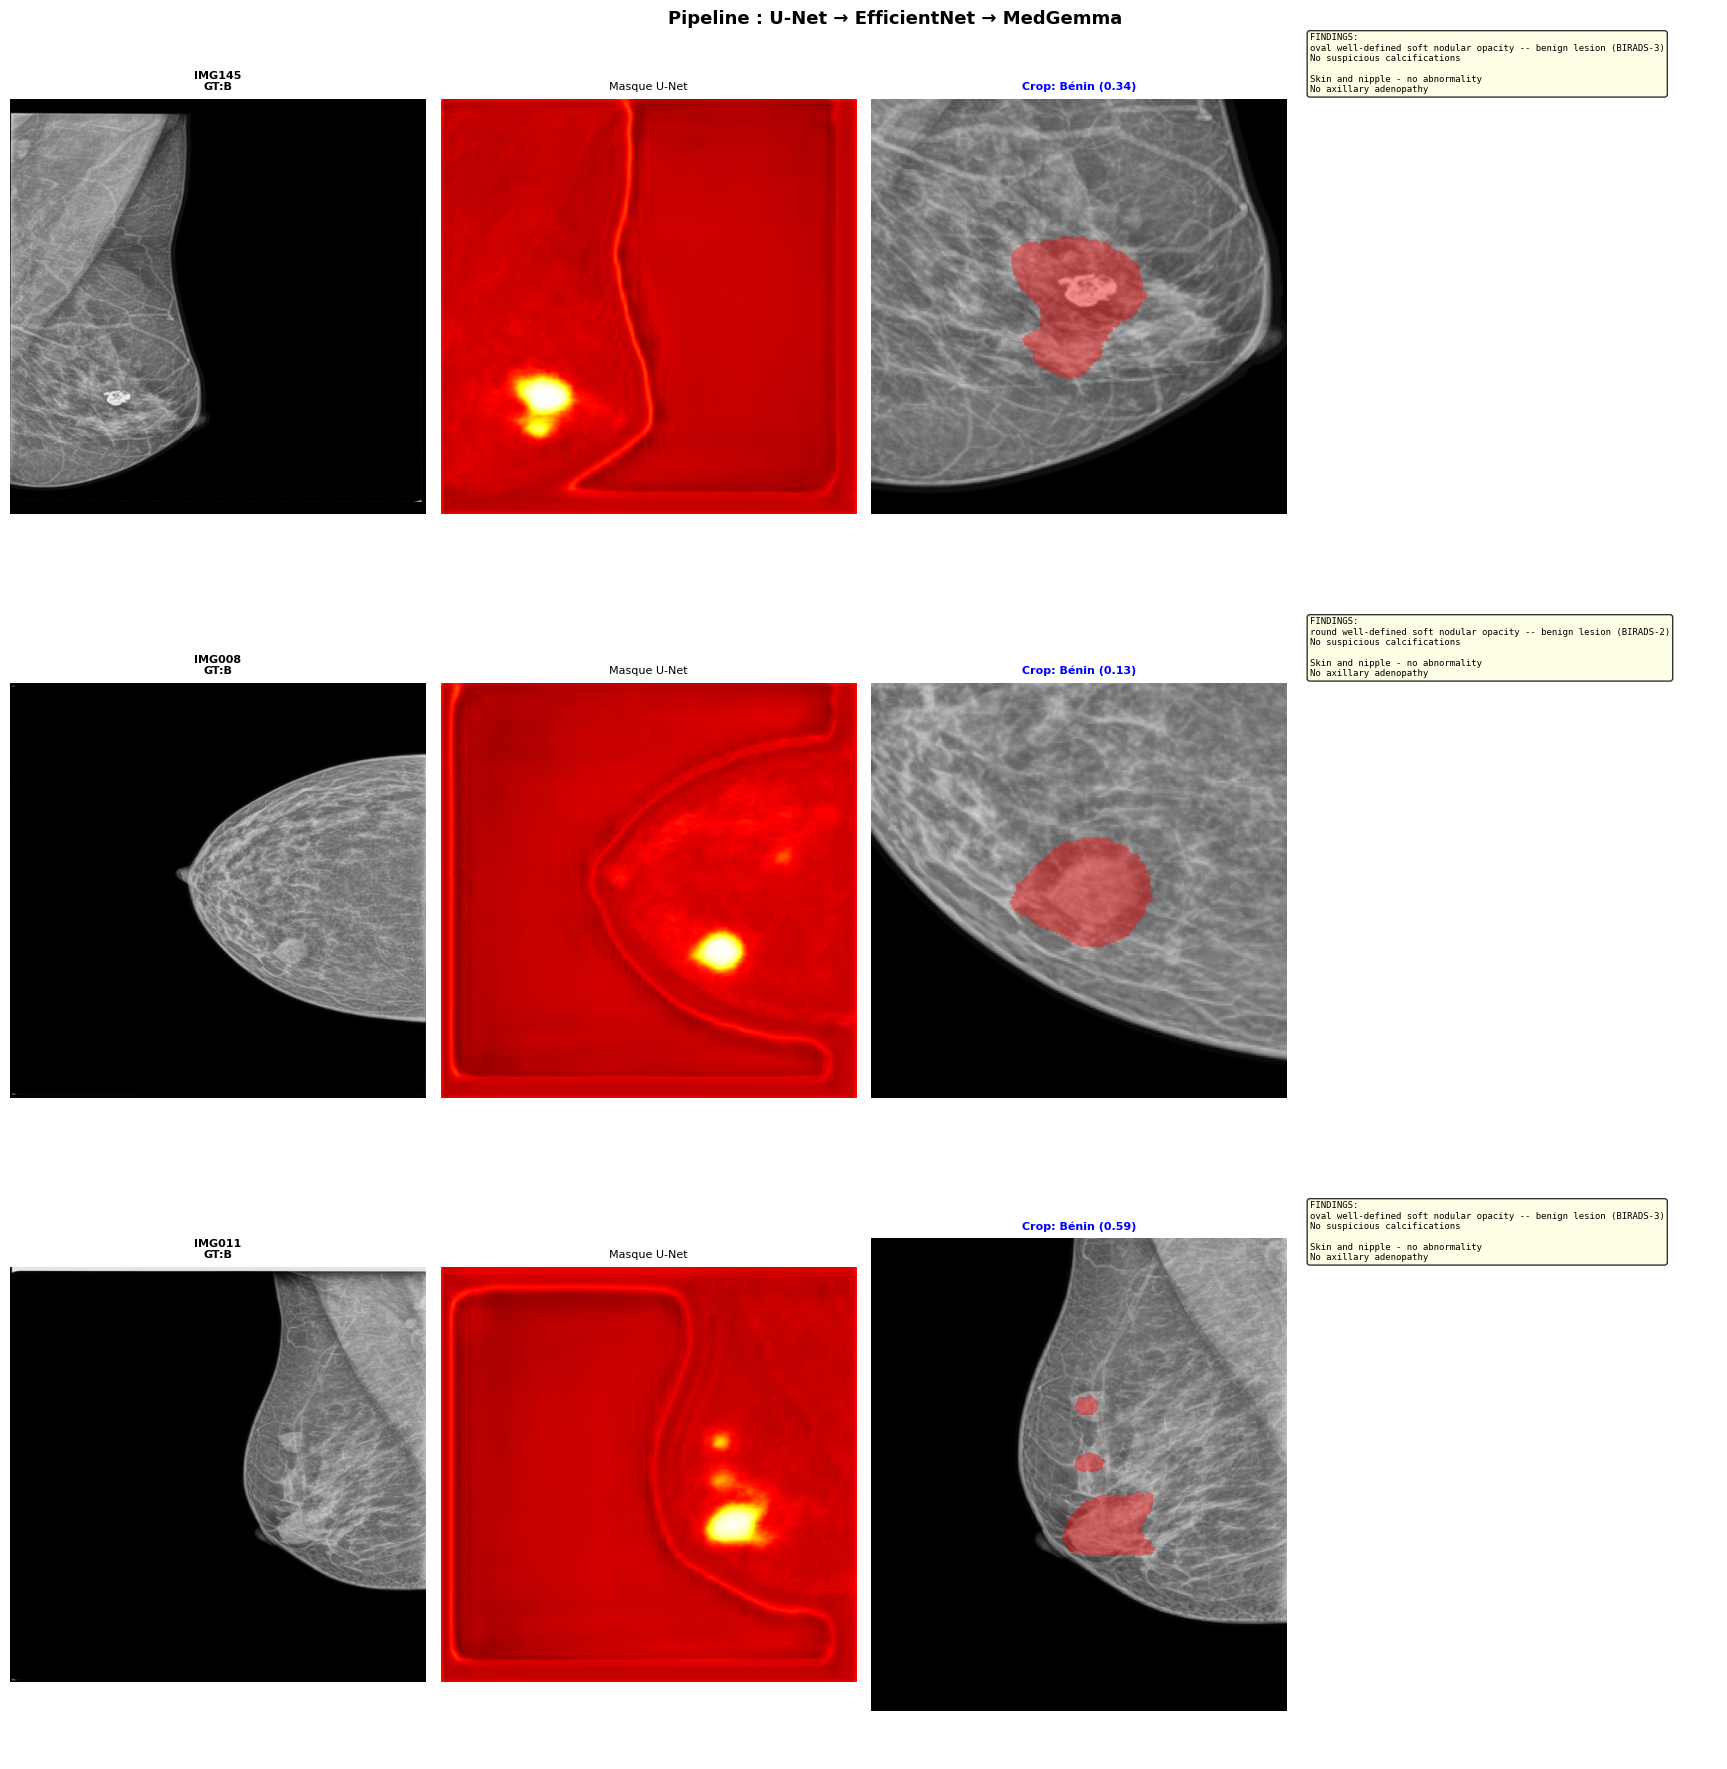

In [41]:
n_show = min(3, len(pipeline_results))
fig = plt.figure(figsize=(18, n_show * 6))

for i, res in enumerate(pipeline_results[:n_show]):
    ax_img  = fig.add_subplot(n_show, 4, i*4+1)
    ax_mask = fig.add_subplot(n_show, 4, i*4+2)
    ax_crop = fig.add_subplot(n_show, 4, i*4+3)
    ax_text = fig.add_subplot(n_show, 4, i*4+4)

    # Col 1 — image originale
    path = get_img_path(res['ref'])
    if path:
        ax_img.imshow(Image.open(path).convert('RGB'))
    ax_img.set_title(f'{res["ref"][:12]}\nGT:{"M" if res["true"]==1 else "B"}',
                     fontsize=8, fontweight='bold')
    ax_img.axis('off')

    # Col 2 — masque U-Net
    ax_mask.imshow(res['mask'], cmap='hot', vmin=0, vmax=1)
    ax_mask.set_title('Masque U-Net', fontsize=8)
    ax_mask.axis('off')

    # Col 3 — crop avec overlay
    ax_crop.imshow(res['overlay'])
    cls_str = 'Malin' if res['pred']==1 else 'Bénin'
    color   = 'red' if res['pred']==1 else 'blue'
    ax_crop.set_title(f'Crop: {cls_str} ({res["prob"]:.2f})',
                      fontsize=8, color=color, fontweight='bold')
    ax_crop.axis('off')

    # Col 4 — FINDINGS du rapport
    ax_text.axis('off')
    findings_short = res['findings'][:600] + '...' \
        if len(res['findings']) > 600 else res['findings']
    ax_text.text(0.02, 0.98, 'FINDINGS:\n' + findings_short,
                transform=ax_text.transAxes,
                fontsize=6.5, verticalalignment='top',
                wrap=True, family='monospace',
                bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

plt.suptitle('Pipeline : U-Net → EfficientNet → MedGemma',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(PFA_PATH,'pipeline_results.png'),
            dpi=150, bbox_inches='tight')
plt.show()


In [42]:
# Affichage du rapport complet pour le premier exemple + comparaison Findings
if pipeline_results:
    res = pipeline_results[0]
    print('='*70)
    print(f'  RAPPORT MEDGEMMA — {res["ref"]}')
    print('='*70)
    print(res['report'])
    print('='*70)

    ref_full = ref_reports.get(res['ref'])
    if ref_full:
        ref_fin = extract_ref_findings(ref_full)
        print('\n' + '='*70)
        print('  RAPPORT DE RÉFÉRENCE (radiologue humain)')
        print('='*70)
        print(ref_full)
        print()
        print('--- Findings extrait (référence) ---')
        print(ref_fin)
        print('--- FINDINGS extrait (MedGemma)  ---')
        print(res['findings'])
        print('-'*50)
        sc = rouge_scorer_obj.score(ref_fin, res['findings'])
        print(f'ROUGE-1      : {sc["rouge1"].fmeasure:.4f}')
        print(f'ROUGE-2      : {sc["rouge2"].fmeasure:.4f}')
        print(f'ROUGE-L      : {sc["rougeL"].fmeasure:.4f}')
        # BERT Cosine pour cette image
        emb_h = bert_model.encode(res['findings'],   convert_to_tensor=True, show_progress_bar=False)
        emb_r = bert_model.encode(ref_fin,           convert_to_tensor=True, show_progress_bar=False)
        import torch.nn.functional as F_
        sim_i = float(F_.cosine_similarity(emb_h.unsqueeze(0), emb_r.unsqueeze(0)))
        print(f'BERT-Cosine  : {sim_i:.4f}')
    else:
        print('\n(Pas de rapport de référence pour cette image)')


  RAPPORT MEDGEMMA — IMG145
Breast Composition:
predominantly fibro fatty breast parenchyma (ACR B)

BIRADS: 3

Findings:
oval well-defined soft nodular opacity -- benign lesion (BIRADS-3)
No suspicious calcifications

Skin and nipple - no abnormality
No axillary adenopathy


  RAPPORT DE RÉFÉRENCE (radiologue humain)
Breast Composition:
fibro fatty and glandular breast parenchyma (ACR B).

BIRADS: 2

Findings:
a benign-looking popcorn calcification is seen in the central quadrant.(BIRADS 2)
skin, nipple, and pectoral muscle appear normal.
benign-looking axillary adenopathy.

--- Findings extrait (référence) ---
a benign-looking popcorn calcification is seen in the central quadrant.(BIRADS 2)
skin, nipple, and pectoral muscle appear normal.
benign-looking axillary adenopathy.
--- FINDINGS extrait (MedGemma)  ---
oval well-defined soft nodular opacity -- benign lesion (BIRADS-3)
No suspicious calcifications

Skin and nipple - no abnormality
No axillary adenopathy
-----------------------

In [43]:
print('='*65)
print('   SYNTHÈSE FINALE — Pipeline DMID')
print('='*65)
print(f'\nDataset')
print(f'  Test set : {len(img_test)} images'
      f' (B:{(img_test.label==0).sum()} / M:{(img_test.label==1).sum()})')

print(f'\nClassification (EfficientNet-B3 + SVM, U-Net crop)')
y_pred_all = [r['pred'] for r in pipeline_results]
y_true_all = [r['true'] for r in pipeline_results]
y_prob_all = [r['prob'] for r in pipeline_results]
if len(set(y_true_all)) > 1:
    auc_final = roc_auc_score(y_true_all, y_prob_all)
    acc_final = accuracy_score(y_true_all, y_pred_all)
    cm_f = confusion_matrix(y_true_all, y_pred_all)
    tn,fp,fn,tp = cm_f.ravel()
    print(f'  AUC         : {auc_final:.4f}')
    print(f'  Accuracy    : {acc_final:.4f}')
    print(f'  Sensibilité : {tp/(tp+fn+1e-8):.4f}  (ne pas manquer les cancers)')
    print(f'  Spécificité : {tn/(tn+fp+1e-8):.4f}')

print(f'\nSegmentation U-Net (test set — voir notebook entraînement)')
print('  Dice : see notebooks/01_training_segmentation_classification.ipynb')

print(f'\nRapports MedGemma ({len(pipeline_results)} générés)')
if rouge_scores['rouge1']:
    print(f'  ROUGE-1      : {np.mean(rouge_scores["rouge1"]):.4f}')
    print(f'  ROUGE-2      : {np.mean(rouge_scores["rouge2"]):.4f}')
    print(f'  ROUGE-L      : {np.mean(rouge_scores["rougeL"]):.4f}')
if bleu_scores['bleu1']:
    print(f'  BLEU-1       : {np.mean(bleu_scores["bleu1"]):.4f}')
    print(f'  BLEU-2       : {np.mean(bleu_scores["bleu2"]):.4f}')
    print(f'  BLEU-4       : {np.mean(bleu_scores["bleu4"]):.4f}')
if bert_sims:
    print(f'  BERT-Cosine  : {np.mean(bert_sims):.4f}')
if not rouge_scores['rouge1'] and not bert_sims:
    print(f'  (aucun rapport de référence évalué)')

print(f'\nModèles utilisés')
print(f'  U-Net    : {UNET_PT}')
print(f'  EfficNet : effnet_unet_classifier.pkl')
print(f'  MedGemma : {MEDGEMMA_ID}')
print('='*65)


   SYNTHÈSE FINALE — Pipeline DMID

Dataset
  Test set : 42 images (B:23 / M:19)

Classification (EfficientNet-B3 + SVM, U-Net crop)
  AUC         : 0.8032
  Accuracy    : 0.8095
  Sensibilité : 0.6316  (ne pas manquer les cancers)
  Spécificité : 0.9565

Segmentation U-Net (test set — voir notebook entraînement)
  Dice : see notebooks/01_training_segmentation_classification.ipynb

Rapports MedGemma (42 générés)
  ROUGE-1      : 0.4418
  ROUGE-2      : 0.2038
  ROUGE-L      : 0.3743
  BLEU-1       : 0.2383
  BLEU-2       : 0.1368
  BLEU-4       : 0.0505
  BERT-Cosine  : 0.7145

Modèles utilisés
  U-Net    : /content/drive/MyDrive/PFA/models/unet_mammo.pt
  EfficNet : effnet_unet_classifier.pkl
  MedGemma : google/medgemma-4b-it


In [44]:
!pip install -q flask flask-cors pyngrok
print('Flask + pyngrok installés')


Flask + pyngrok installés


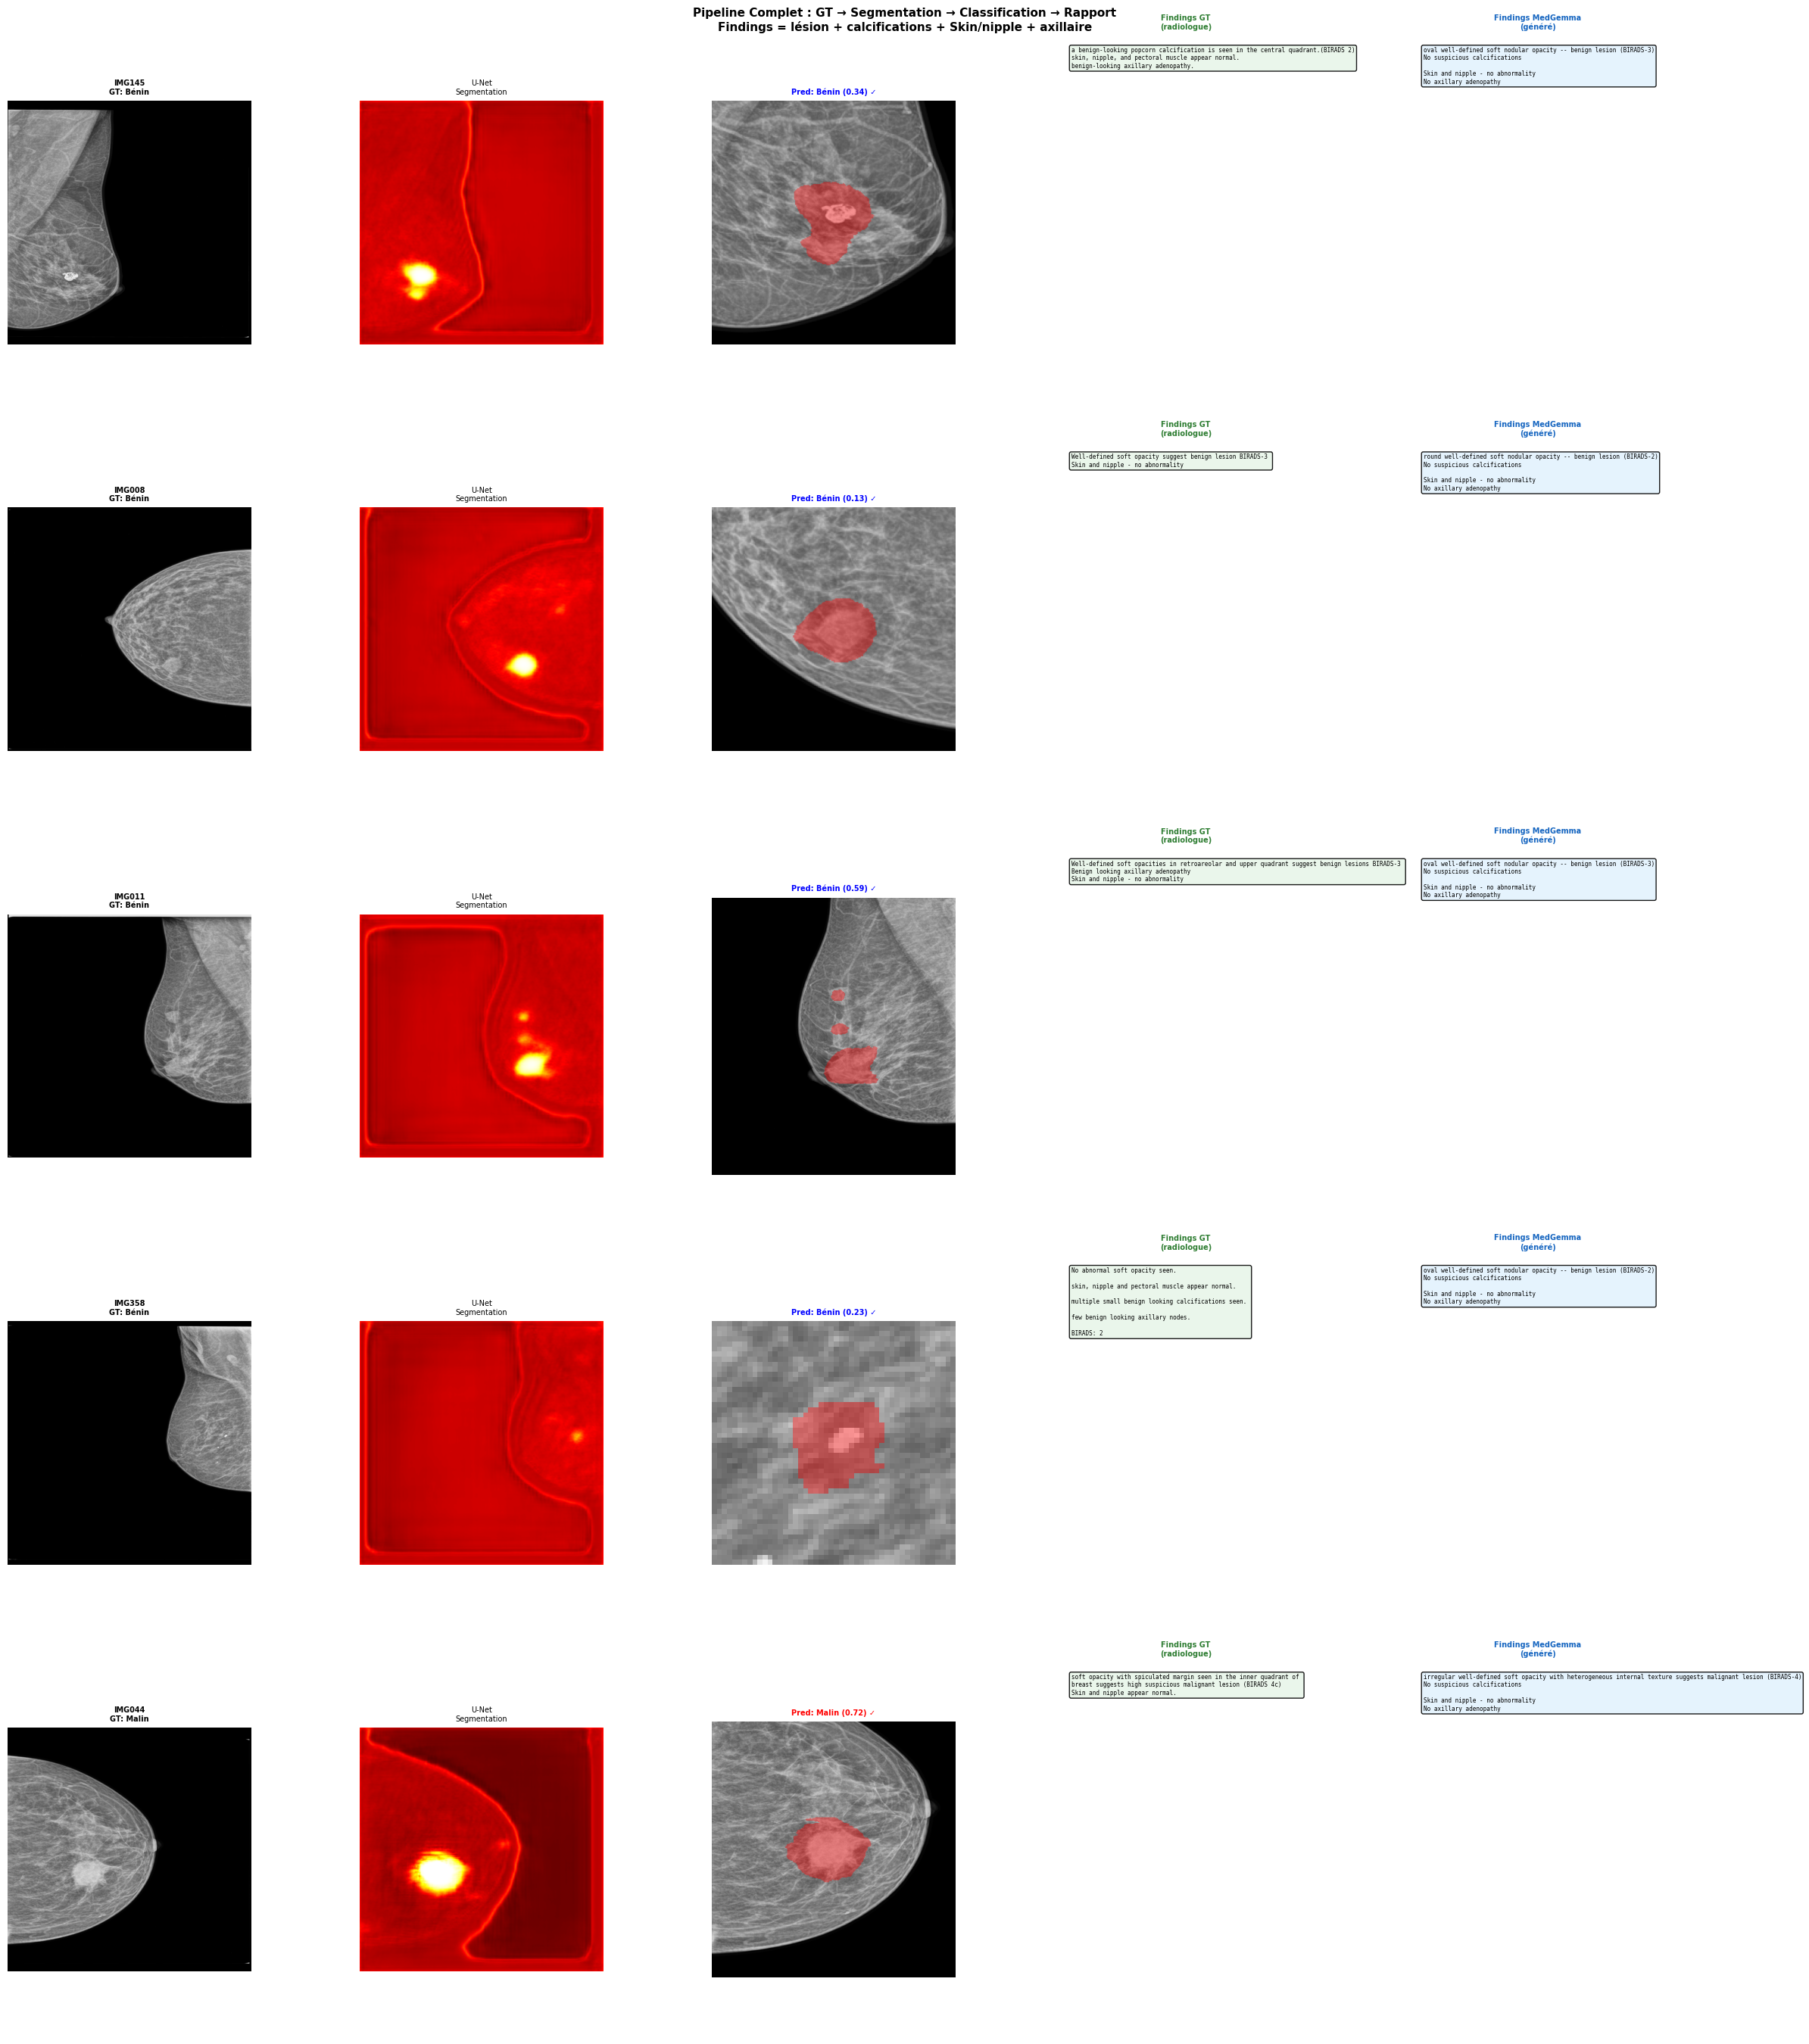

✓ Figure sauvegardée : pipeline_gt_vs_medgemma.png
  5/42 images avec rapport GT affichées


In [45]:
# Visualisation complète : image originale / masque U-Net / crop+classification
#                          / Findings GT (radiologue) / Findings MedGemma
# Findings = tout ce qui suit 'Findings:' (lésion + calcifications + Skin/nipple + axillaire)

results_with_ref = [r for r in pipeline_results if r['ref'] in ref_reports]
n_show = min(5, len(results_with_ref))

if n_show == 0:
    print('⚠️  Aucun rapport GT disponible — vérifier le dossier Reports/')
else:
    fig = plt.figure(figsize=(24, n_show * 5.5))

    for i, res in enumerate(results_with_ref[:n_show]):
        ax_img  = fig.add_subplot(n_show, 5, i*5+1)
        ax_mask = fig.add_subplot(n_show, 5, i*5+2)
        ax_crop = fig.add_subplot(n_show, 5, i*5+3)
        ax_gt   = fig.add_subplot(n_show, 5, i*5+4)
        ax_gen  = fig.add_subplot(n_show, 5, i*5+5)

        # ── Col 1 : Image originale ───────────────────────────────────────────
        path = get_img_path(res['ref'])
        if path:
            ax_img.imshow(Image.open(path).convert('RGB'))
        gt_lbl   = 'Malin' if res['true']==1 else 'Bénin'
        ax_img.set_title(f'{res["ref"][:12]}\nGT: {gt_lbl}',
                         fontsize=7, fontweight='bold')
        ax_img.axis('off')

        # ── Col 2 : Masque U-Net ──────────────────────────────────────────────
        ax_mask.imshow(res['mask'], cmap='hot', vmin=0, vmax=1)
        ax_mask.set_title('U-Net\nSegmentation', fontsize=7)
        ax_mask.axis('off')

        # ── Col 3 : Crop + overlay + classification ───────────────────────────
        ax_crop.imshow(res['overlay'])
        pred_lbl = 'Malin' if res['pred']==1 else 'Bénin'
        col      = 'red' if res['pred']==1 else 'blue'
        correct  = '✓' if res['pred']==res['true'] else '✗'
        ax_crop.set_title(f'Pred: {pred_lbl} ({res["prob"]:.2f}) {correct}',
                          fontsize=7, color=col, fontweight='bold')
        ax_crop.axis('off')

        # ── Col 4 : Findings GT — tout ce qui suit 'Findings:' ───────────────
        ref_text  = ref_reports.get(res['ref'], '')
        ref_fin   = extract_ref_findings(ref_text)  # re.DOTALL → inclut Skin/nipple + axillaire
        ref_short = ref_fin[:450] + '...' if len(ref_fin) > 450 else ref_fin
        ax_gt.axis('off')
        ax_gt.set_title('Findings GT\n(radiologue)', fontsize=7,
                        fontweight='bold', color='#2e7d32')
        ax_gt.text(0.03, 0.97, ref_short,
                   transform=ax_gt.transAxes, fontsize=5.5,
                   verticalalignment='top', wrap=True, family='monospace',
                   bbox=dict(boxstyle='round', facecolor='#e8f5e9', alpha=0.9))

        # ── Col 5 : Findings MedGemma — tout ce qui suit 'Findings:' ─────────
        gen_fin   = res['findings']  # extrait par extract_findings_section (re.DOTALL)
        gen_short = gen_fin[:450] + '...' if len(gen_fin) > 450 else gen_fin
        ax_gen.axis('off')
        ax_gen.set_title('Findings MedGemma\n(généré)', fontsize=7,
                         fontweight='bold', color='#1565c0')
        ax_gen.text(0.03, 0.97, gen_short,
                    transform=ax_gen.transAxes, fontsize=5.5,
                    verticalalignment='top', wrap=True, family='monospace',
                    bbox=dict(boxstyle='round', facecolor='#e3f2fd', alpha=0.9))

    plt.suptitle(
        'Pipeline Complet : GT → Segmentation → Classification → Rapport\n'
        'Findings = lésion + calcifications + Skin/nipple + axillaire',
        fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(PFA_PATH, 'pipeline_gt_vs_medgemma.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    print(f'✓ Figure sauvegardée : pipeline_gt_vs_medgemma.png')
    print(f'  {n_show}/{len(results_with_ref)} images avec rapport GT affichées')


In [ ]:
import base64, io, threading
from flask import Flask, request, jsonify
from flask_cors import CORS
from pyngrok import ngrok, conf

app = Flask(__name__)
CORS(app)  # autorise les requêtes depuis Angular localhost:4200

def image_to_b64(pil_img):
    buf = io.BytesIO()
    pil_img.save(buf, format='PNG')
    return base64.b64encode(buf.getvalue()).decode()

@app.route('/health', methods=['GET'])
def health():
    return jsonify({'status': 'ok', 'models': 'loaded'})

@app.route('/predict', methods=['POST'])
def predict():
    if 'image' not in request.files:
        return jsonify({'error': 'Aucune image reçue'}), 400

    file = request.files['image']
    try:
        img = Image.open(file.stream).convert('RGB')
    except Exception as e:
        return jsonify({'error': f'Image invalide : {e}'}), 400

    # ── Pipeline inference ────────────────────────────────────────────────────
    # 1. U-Net → masque
    mask_f = run_unet(img)

    # 2. Crop
    crop, mask_crop, bbox = mask_to_crop(img, mask_f)

    # 3. EfficientNet → features
    t = FEAT_TF(crop).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        feat = feat_ext(t).cpu().numpy()
    feat_s = scaler.transform(feat)

    # 4. SVM → classification
    prob = float(best_clf.predict_proba(feat_s)[0, 1])
    pred = int(prob >= best_thr)  # seuil Youden

    # 5. Features radiologiques
    feats_r = extract_radiomic(mask_f, img)

    # 6. Overlay
    overlay = make_overlay(crop, mask_crop)

    # 7. MedGemma → rapport
    prompt  = build_prompt('upload', 'MLO', 'heterogeneous', pred, prob, feats_r)
    report  = generate_report(overlay, prompt)
    findings = extract_findings_section(report)

    # 8. BIRADS depuis rapport
    birads_m = re.search(r'BIRADS\s*:\s*(\d)', report)
    birads   = birads_m.group(1) if birads_m else '?'

    return jsonify({
        'classification': 'Malin' if pred == 1 else 'Bénin',
        'probability':    round(prob * 100, 1),
        'birads':         birads,
        'report':         report,
        'findings':       findings,
        'overlay_b64':    image_to_b64(overlay),
        'crop_b64':       image_to_b64(crop),
    })

# ── Démarrage ngrok + Flask ───────────────────────────────────────────────────
try:
    from google.colab import userdata
    NGROK_TOKEN = userdata.get('NGROK_TOKEN')   # Colab secret
except Exception:
    import os
    NGROK_TOKEN = os.environ.get('NGROK_TOKEN')
conf.get_default().auth_token = NGROK_TOKEN

public_url = ngrok.connect(5000)
print('='*60)
print(f'  API publique : {public_url}')
print(f'  Health check : {public_url}/health')
print(f'  Endpoint     : {public_url}/predict  (POST, multipart image)')
print('='*60)
print('Coller cette URL dans Angular environment.ts')
print('Ctrl+C pour arrêter')

# Flask dans un thread pour ne pas bloquer Colab
t = threading.Thread(target=lambda: app.run(port=5000, use_reloader=False))
t.daemon = True
t.start()

# Garder la cellule active
import time
while True:
    time.sleep(60)


  API publique : NgrokTunnel: "https://<your-ngrok-subdomain>.ngrok-free.dev" -> "http://localhost:5000"
  Health check : NgrokTunnel: "https://<your-ngrok-subdomain>.ngrok-free.dev" -> "http://localhost:5000"/health
  Endpoint     : NgrokTunnel: "https://<your-ngrok-subdomain>.ngrok-free.dev" -> "http://localhost:5000"/predict  (POST, multipart image)
Coller cette URL dans Angular environment.ts
Ctrl+C pour arrêter
 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit
INFO:werkzeug:127.0.0.1 - - [08/Jun/2026 01:52:12] "POST /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [08/Jun/2026 01:53:30] "POST /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [08/Jun/2026 01:54:08] "POST /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [08/Jun/2026 01:54:43] "POST /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [08/Jun/2026 01:55:11] "POST /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [08/Jun/2026 01:56:17] "POST /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [08/Jun/2026 02:00:08] "POST /predict HTTP/1.1" 200 -
